In [48]:
import csv
import os

import matplotlib.pyplot as plt

RESULTS_DIR = "results"


def plot_sweep(filename, column, ignore=[]):
    """Plot `column` of a sweep CSV in results/ against the error-rate scaling epsilon.

    The x-axis is logarithmic, so the epsilon = 0 (noise-free) row is left out. Two extra axes
    along the top give the matching depolarizing weights lambda_cz and lambda_sx (lambda = epsilon * rate).
    `ignore` lists plotted points to leave out, counted from 1 (1 = the leftmost point).
    """
    with open(os.path.join(RESULTS_DIR, filename), newline="") as f:
        rows = []
        i = 0
        for line in csv.DictReader(f):
            if float(line["epsilon"]) <= 0:
                continue
            i += 1
            if i in ignore:
                continue
            rows.append(line)
    epsilons = [float(row["epsilon"]) for row in rows]
    values = [float(row[column]) for row in rows]

    fig, ax = plt.subplots()
    ax.plot(epsilons, values, marker="o")
    ax.set_xscale("log")
    ax.set_xlabel("epsilon")
    ax.set_ylabel(column)
    ax.set_title(filename)
    ax.grid(True, which="both", alpha=0.3)

    # lambda is linear in epsilon, so each gate's axis is the epsilon axis rescaled by its rate.
    for gate, offset in [("cz", 1.0), ("sx", 1.25)]:
        rate = float(rows[0][f"lambda_{gate}"]) / epsilons[0]
        top = ax.secondary_xaxis(offset, functions=(lambda e, r=rate: e * r, lambda l, r=rate: l / r))
        top.set_xlabel(f"lambda_{gate}")
    return fig, ax


def plot_both(first, second):
    """Overlay the points of two plot_sweep results on one diagram.

    `first` and `second` are the (fig, ax) pairs plot_sweep returns. Their own figures are closed
    so only the combined one is shown.
    """
    fig, ax = plt.subplots()
    columns = []
    for old_fig, old_ax in (first, second):
        line = old_ax.lines[0]
        ax.plot(line.get_xdata(), line.get_ydata(), marker="o", label=old_ax.get_title())
        if old_ax.get_ylabel() not in columns:
            columns.append(old_ax.get_ylabel())
        plt.close(old_fig)

    ax.set_xscale("log")
    ax.set_xlabel("epsilon")
    ax.set_ylabel(" / ".join(columns))
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
    return fig, ax


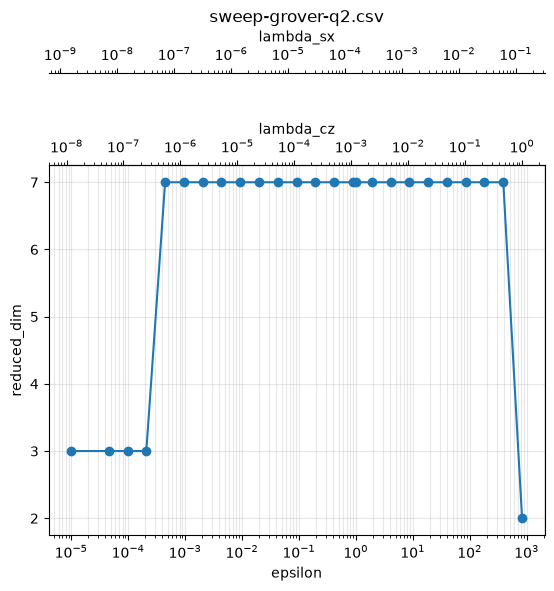

In [38]:
plot_sweep("sweep-grover-q2.csv", "reduced_dim", ignore=[2]);

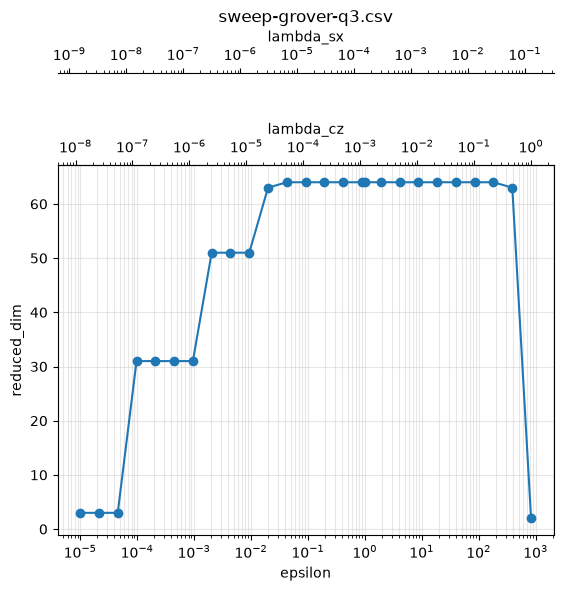

In [2]:
plot_sweep("sweep-grover-q3.csv", "reduced_dim");

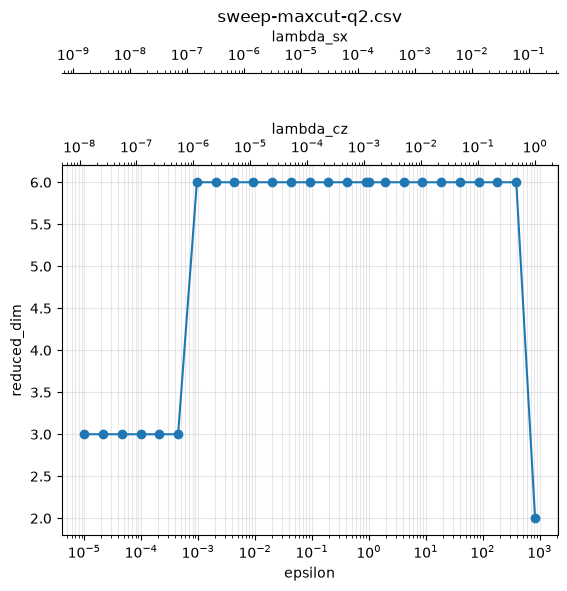

In [6]:
plot_sweep("sweep-maxcut-q2.csv", "reduced_dim");

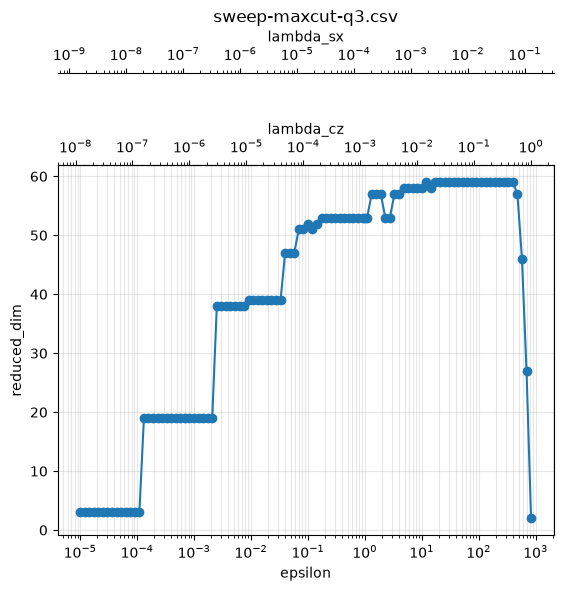

In [7]:
plot_sweep("sweep-maxcut-q3.csv", "reduced_dim");

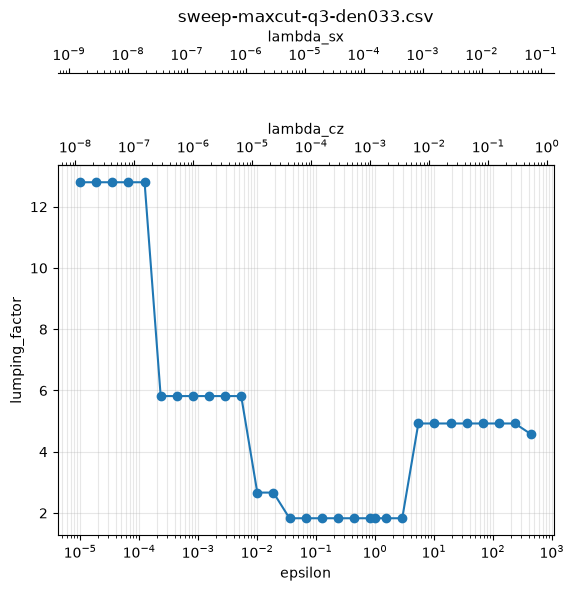

In [43]:
plot_sweep("sweep-maxcut-q3-den033.csv", "lumping_factor", ignore=[31]);

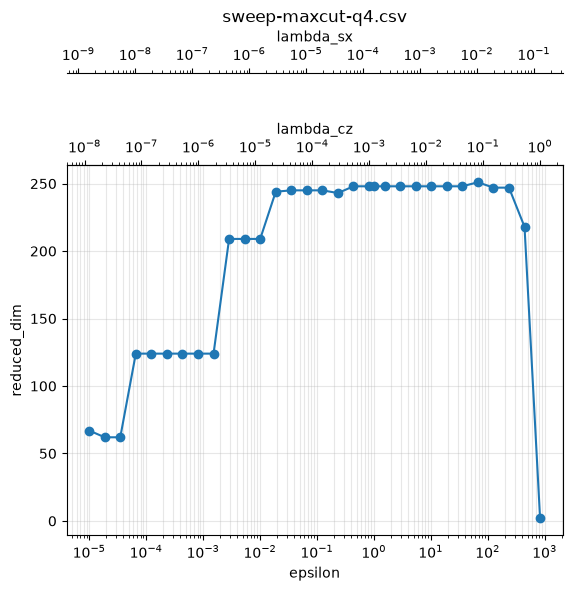

In [4]:
plot_sweep("sweep-maxcut-q4.csv", "reduced_dim");

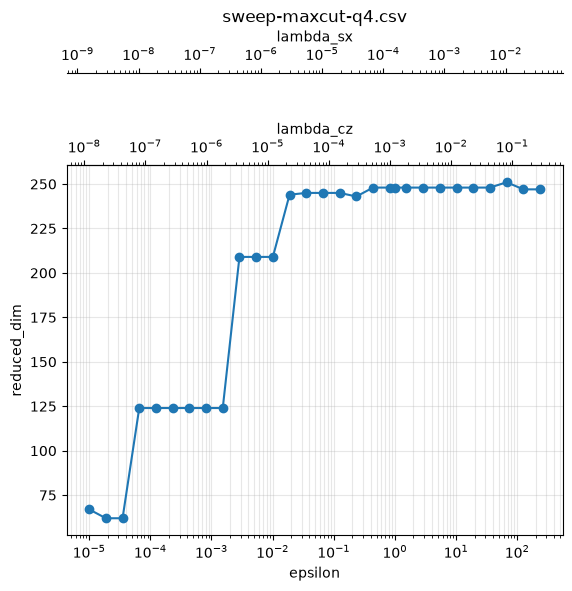

In [46]:
plot_sweep("sweep-maxcut-q4.csv", "reduced_dim", ignore=[30, 31]);

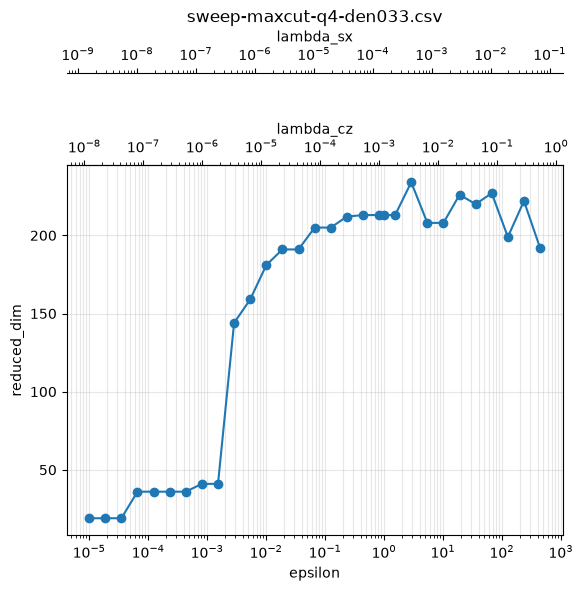

In [49]:
plot_sweep("sweep-maxcut-q4-den033.csv", "reduced_dim", ignore=[31]);

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='epsilon', ylabel='lumping_factor'>)

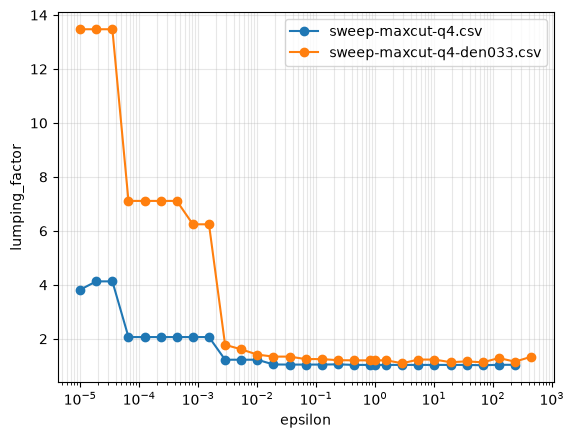

In [51]:
plot_both(
    plot_sweep("sweep-maxcut-q4.csv", "lumping_factor", ignore=[30, 31]),
    plot_sweep("sweep-maxcut-q4-den033.csv", "lumping_factor", ignore=[31])
)